In [5]:
pip install pandas numpy scikit-learn seaborn statsmodels matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from numpy import mean
from numpy import absolute


df = pd.read_csv("2154346boston.csv")
df.head()

,MEDV,CRIM,INDUS,HIDEM,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LANDMARK
0,234,13.91340,18.10,no,0.713,6.208,95.0,2.2222,24,666,20.2,No Landmark
1,488,0.22969,10.59,no,0.489,6.326,52.5,4.3549,4,277,18.6,No Landmark
2,326,28.65580,18.10,no,0.597,5.155,100.0,1.5894,24,666,20.2,No Landmark
3,312,0.75026,8.14,no,0.538,5.924,94.1,4.3996,4,307,21.0,No Landmark
4,362,0.55778,21.89,no,0.624,6.335,98.2,2.1107,4,437,21.2,No Landmark


          MEDV        RM       AGE
MEDV  1.000000  0.690109 -0.364702
RM    0.690109  1.000000 -0.233972
AGE  -0.364702 -0.233972  1.000000


<Axes: >

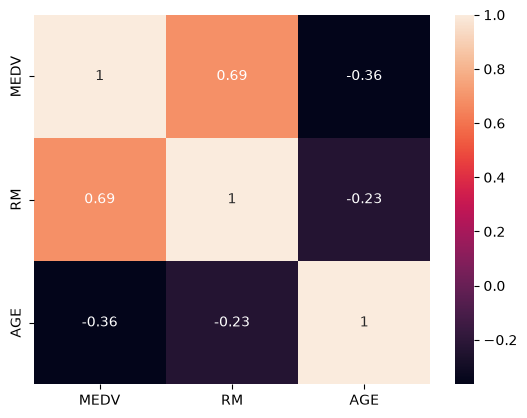

In [7]:
data = df[['MEDV','RM','AGE']]
matrix = data.corr()
print(matrix)

import seaborn as sn
sn.heatmap(matrix, annot=True)

In [8]:
import statsmodels.api as sm

y = df['MEDV'] 

X = df.drop(columns=['MEDV'])
X = sm.add_constant(X)
X =pd.get_dummies(X, drop_first=True, dtype=int)
model = sm.OLS(y, X).fit() #fit the model to the data
print(model.summary()) #print the results

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.888
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                     249.2
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          5.73e-199
Time:                        13:16:02   Log-Likelihood:                -2521.7
No. Observations:                 455   AIC:                             5073.
Df Residuals:                     440   BIC:                             5135.
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                   1149

In [9]:
# VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant
 
# Select independent variables
X = df.drop(columns=['MEDV'])
 
# Convert categorical variables into dummy variables
X = pd.get_dummies(X, columns=['HIDEM', 'LANDMARK'], drop_first=True, dtype=int)
 
# Add constant
X = add_constant(X)
 
# Create a dataframe that contains the VIF values
VIF_data = pd.DataFrame()
VIF_data["variable"] = X.columns
VIF_data["VIF"] = [vif(X, i)
                   for i in range(len(X.columns))]
 
print(VIF_data)

                  variable        VIF
0                    const   1.000000
1                     CRIM   1.667981
2                    INDUS   4.206586
3                      NOX   4.388807
4                       RM   1.946002
5                      AGE   2.679479
6                      DIS   3.574493
7                      RAD   8.100460
8                      TAX   9.063214
9                  PTRATIO   1.775950
10               HIDEM_yes   1.113669
11    LANDMARK_No Landmark  11.122662
12           LANDMARK_Park   5.667592
13  LANDMARK_Shopping Mall   5.170753
14        LANDMARK_Stadium   2.026901


In [10]:

import statsmodels.api as sm

y = df['MEDV'] 

X = df.drop(columns=['MEDV','TAX'])
X = sm.add_constant(X)
X =pd.get_dummies(X, drop_first=True, dtype=int)
model = sm.OLS(y, X).fit() #fit the model to the data
print(model.summary()) #print the results

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.885
Model:                            OLS   Adj. R-squared:                  0.882
Method:                 Least Squares   F-statistic:                     260.8
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          1.38e-197
Time:                        13:16:02   Log-Likelihood:                -2527.9
No. Observations:                 455   AIC:                             5084.
Df Residuals:                     441   BIC:                             5142.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                   1115

In [11]:
# VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from statsmodels.tools.tools import add_constant
 
# Select independent variables
X = df.drop(columns=['MEDV'])
 
# Convert categorical variables into dummy variables
X = pd.get_dummies(X, columns=['HIDEM', 'LANDMARK'], drop_first=True, dtype=int)

X = X.drop(columns=['TAX'])
 
# Add constant
X = add_constant(X)
 
# Create a dataframe that contains the VIF values
VIF_data = pd.DataFrame()
VIF_data["variable"] = X.columns
VIF_data["VIF"] = [vif(X, i)
                   for i in range(len(X.columns))]
 
print(VIF_data)

                  variable        VIF
0                    const   1.000000
1                     CRIM   1.667676
2                    INDUS   3.585907
3                      NOX   4.367320
4                       RM   1.943308
5                      AGE   2.679321
6                      DIS   3.525083
7                      RAD   2.805156
8                  PTRATIO   1.773718
9                HIDEM_yes   1.100316
10    LANDMARK_No Landmark  11.121166
11           LANDMARK_Park   5.667438
12  LANDMARK_Shopping Mall   5.167111
13        LANDMARK_Stadium   2.026852


Multiculinarity is not a problem with the landmark variale because this variable is one variable devided by four.

***Assignment 2***


In [12]:
import matplotlib.pyplot as plt

In [13]:
from matplotlib.pylab import absolute, mean
from sklearn.model_selection import RepeatedKFold

cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=1)

X = df.drop(columns=['MEDV'])
X = pd.get_dummies(X, drop_first=True, dtype=int)
y = df['MEDV']

lm = LinearRegression()
lmscores = cross_val_score(lm, X, y, #these define the type of model, features, and target
                           scoring='neg_mean_absolute_error', #test using mean absolute deviation
                           cv=5) #use cross-validation with 5 folds


lmMAE = mean(absolute(lmscores)) #Calculate the overall mean absolute error
print('the average prediction error with full data is: %.0f' % lmMAE) #Print the result

the average prediction error with full data is: 49


In [14]:
import pandas as pd
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from numpy import mean
from numpy import absolute
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV
import numpy as np


In [15]:
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

In [16]:
pip install optuna


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
#Hyperparameter Tuning
import optuna
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

# Hyperparameter tuning
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 250, step=10),
        'max_depth': trial.suggest_int('max_depth', 10, 250, step=10),
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 30, step=1),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        'random_state': 69
    }
    regressor = RandomForestRegressor(**params)
    score = cross_val_score(regressor, X, y, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1).mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)  # search across 100 different combinations

print("Best params:", study.best_params)

[I 2026-10-30 13:16:03,537] A new study created in memory with name: no-name-9658dcb9-4234-417f-a921-8ca4241c1923
[I 2026-10-30 13:16:09,119] Trial 0 finished with value: -43.55289646762234 and parameters: {'n_estimators': 130, 'max_depth': 10, 'min_samples_split': 26, 'max_features': None}. Best is trial 0 with value: -43.55289646762234.
[I 2026-10-30 13:16:09,318] Trial 1 finished with value: -47.97912722758914 and parameters: {'n_estimators': 30, 'max_depth': 30, 'min_samples_split': 12, 'max_features': 'log2'}. Best is trial 0 with value: -43.55289646762234.
[I 2026-10-30 13:16:10,282] Trial 2 finished with value: -47.007934273057096 and parameters: {'n_estimators': 190, 'max_depth': 100, 'min_samples_split': 16, 'max_features': 'log2'}. Best is trial 0 with value: -43.55289646762234.
[I 2026-10-30 13:16:11,633] Trial 3 finished with value: -39.506461455502794 and parameters: {'n_estimators': 160, 'max_depth': 240, 'min_samples_split': 14, 'max_features': None}. Best is trial 3 wit

Best params: {'n_estimators': 170, 'max_depth': 230, 'min_samples_split': 10, 'max_features': None}


In [18]:
regressor = RandomForestRegressor(**study.best_params,
                                      random_state=69) 
RFscores = cross_val_score(regressor, X, y, cv=5,
                           scoring='neg_mean_absolute_error')
MAE = mean(absolute(RFscores))
print ('the MAE is: %.2f' % MAE)

the MAE is: 38.63


In [53]:
#Calculate Gini importance

rf.fit(X,y) #Fit the data to the random forest model
feature_importances = rf.feature_importances_ #get the GINI importances

importance_df = pd.DataFrame({ #create a dataframe shat shows the importance for each feature
    'Feature': X.columns,
    'Importance': feature_importances
})

importance_df = importance_df.sort_values(by='Importance', ascending=False) #sort the data from high to low

print(importance_df) #print the result

                   Feature  Importance
5                      AGE    0.135174
4                       RM    0.134228
6                      DIS    0.133865
0                     MEDV    0.127543
1                     CRIM    0.119190
3                      NOX    0.087428
2                    INDUS    0.064550
8                      TAX    0.063218
9                  PTRATIO    0.059639
7                      RAD    0.029938
12  LANDMARK_Shopping Mall    0.021875
10    LANDMARK_No Landmark    0.012285
11           LANDMARK_Park    0.007146
13        LANDMARK_Stadium    0.003922


In [20]:
pip install tensorflow


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [21]:
pip install scikeras


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import RepeatedKFold
from sklearn.model_selection import cross_val_score
from numpy import mean
from numpy import absolute
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GridSearchCV
import tensorflow as tf
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import KFold
import optuna

df.head()

,MEDV,CRIM,INDUS,HIDEM,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LANDMARK
0,234,13.91340,18.10,no,0.713,6.208,95.0,2.2222,24,666,20.2,No Landmark
1,488,0.22969,10.59,no,0.489,6.326,52.5,4.3549,4,277,18.6,No Landmark
2,326,28.65580,18.10,no,0.597,5.155,100.0,1.5894,24,666,20.2,No Landmark
3,312,0.75026,8.14,no,0.538,5.924,94.1,4.3996,4,307,21.0,No Landmark
4,362,0.55778,21.89,no,0.624,6.335,98.2,2.1107,4,437,21.2,No Landmark


In [23]:
#Hyperparameter Tuning (warning, takes at least 15 minutes)

# Define the function to create the model
def build_model(n_layers=3, n_units=64, activation='softplus'): #start with some inital parameters
    nnmodel = tf.keras.models.Sequential() #define the model
    nnmodel.add(tf.keras.layers.Input(shape=(X.shape[1],)))  # Input layer
    for _ in range(n_layers): #create a for loop that goes through the number of layers, number of units, and activation types
        nnmodel.add(tf.keras.layers.Dense(n_units, activation=activation))
    nnmodel.add(tf.keras.layers.Dense(1))  # Output layer
    nnmodel.compile(loss='mean_absolute_error', optimizer='adam', metrics=['mae']) #compile the model and use mean absolute error as measure of fit
    return nnmodel

def objective(trial):
    # Suggest hyperparameters
    n_layers = trial.suggest_categorical('n_layers', [1, 2, 3, 4, 5])         # Number of hidden layers
    n_units = trial.suggest_categorical('n_units', [32, 64, 128, 256, 512])   # Number of nodes per hidden layer
    activation = trial.suggest_categorical('activation', ['relu', 'tanh', 'softplus', 'elu'])  # activation function
    epochs = trial.suggest_categorical('epochs', [50, 100, 150, 200])         # number of epochs
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])        # number of batches

    # Manual 5-fold CV (Keras models aren't natively supported by cross_val_score)
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    mae_scores = []

    for train_idx, val_idx in kf.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        nnmodel = build_model(n_layers=n_layers, n_units=n_units, activation=activation)
        nnmodel.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)

        val_loss, val_mae = nnmodel.evaluate(X_val, y_val, verbose=0)
        mae_scores.append(val_mae)

    return np.mean(mae_scores)

# search across 10 different combinations
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=10)

print("Best parameters found: ", study.best_params) #print the best parameters

[I 2026-10-30 13:18:19,052] A new study created in memory with name: no-name-a8144e78-735a-4ade-bc53-4b34946f11de


E0000 00:00:1793366299.247252  139319 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50

[I 2026-10-30 13:19:14,610] Trial 0 finished with value: 277.877783203125 and parameters: {'n_layers': 2, 'n_units': 128, 'activation': 'tanh', 'epochs': 200, 'batch_size': 64}. Best is trial 0 with value: 277.877783203125.
[I 2026-10-30 13:19:54,730] Trial 1 finished with value: 54.1332275390625 and parameters: {'n_layers': 5, 'n_units': 512, 'activation': 'elu', 'epochs': 50, 'batch_size': 64}. Best is trial 1 with value: 54.1332275390625.
[I 2026-10-30 13:20:47,987] Trial 2 finished with value: 55.8265625 and parameters: {'n_layers': 2, 'n_units': 256, 'activation': 'relu', 'epochs': 200, 'batch_size': 64}. Best is trial 1 with value: 54.1332275390625.
[I 2026-10-30 13:22:14,285] Trial 3 finished with value: 39.88132553100586 and parameters: {'n_layer

Best parameters found:  {'n_layers': 5, 'n_units': 64, 'activation': 'relu', 'epochs': 200, 'batch_size': 16}


In [25]:
#Neural network with cross validation (first attempt)

#First define a function that contains the neural network model
def create_baseline():
    # create model
    nnmodel = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(X.shape[1],)),  # Input layer 
        tf.keras.layers.Dense(64, activation='relu'), #hidden layer
        tf.keras.layers.Dense(64, activation='relu'), #hidden layer
        tf.keras.layers.Dense(64, activation='relu'), #hidden layer
        tf.keras.layers.Dense(64, activation='relu'), #hidden layer
        tf.keras.layers.Dense(64, activation='relu'), #hidden layer
        tf.keras.layers.Dense(1)  # Output layer
    ])
    # Compile model
    nnmodel.compile(loss='mean_absolute_error', #loss is calculated with MAE
                    optimizer='adam', #type of gradient descent
                    metrics=['mae']) #use MAE to evaluate the model
    return nnmodel

# evaluate model 

#define the estimator
estimator = KerasRegressor(build_fn=create_baseline, #you have to use the kerasRegressor wrapper for nn models
                           epochs=200, batch_size=16, #100 epochs and  batches
                           verbose=0) #this will shorten the output text
#Define the kfold function
kfold = RepeatedKFold(n_splits=5, n_repeats=1, random_state=42) #I'm using just 5 splits and 1 repeat to save time, but more splits and repeats will be more accurate
#Generate the results
results = cross_val_score(estimator, X, y, cv=kfold,scoring='neg_mean_absolute_error')
#Print the results
print('the average prediction error is: %.0f' % mean(absolute(results)))

/usr/local/python/3.14.2/lib/python3.14/site-packages/scikeras/wrappers.py:925: UserWarning: ``build_fn`` will be renamed to ``model`` in a future release, at which point use of ``build_fn`` will raise an Error instead.
  X, y = self._initialize(X, y)
/usr/local/python/3.14.2/lib/python3.14/site-packages/scikeras/wrappers.py:925: UserWarning: ``build_fn`` will be renamed to ``model`` in a future release, at which point use of ``build_fn`` will raise an Error instead.
  X, y = self._initialize(X, y)


/usr/local/python/3.14.2/lib/python3.14/site-packages/scikeras/wrappers.py:925: UserWarning: ``build_fn`` will be renamed to ``model`` in a future release, at which point use of ``build_fn`` will raise an Error instead.
  X, y = self._initialize(X, y)


/usr/local/python/3.14.2/lib/python3.14/site-packages/scikeras/wrappers.py:925: UserWarning: ``build_fn`` will be renamed to ``model`` in a future release, at which point use of ``build_fn`` will raise an Error instead.
  X, y = self._initialize(X, y)
/usr/local/python/3.14.2/lib/python3.14/site-packages/scikeras/wrappers.py:925: UserWarning: ``build_fn`` will be renamed to ``model`` in a future release, at which point use of ``build_fn`` will raise an Error instead.
  X, y = self._initialize(X, y)


the average prediction error is: 40


In [38]:
X = df.drop(columns=['HIDEM'])
X = pd.get_dummies(X, drop_first=True, dtype=int)

y = (df['HIDEM'] == 'yes').astype(int)
print(X.head())
print(y.head())


   MEDV      CRIM  INDUS    NOX     RM    AGE     DIS  RAD  TAX  PTRATIO  \
0   234  13.91340  18.10  0.713  6.208   95.0  2.2222   24  666     20.2   
1   488   0.22969  10.59  0.489  6.326   52.5  4.3549    4  277     18.6   
2   326  28.65580  18.10  0.597  5.155  100.0  1.5894   24  666     20.2   
3   312   0.75026   8.14  0.538  5.924   94.1  4.3996    4  307     21.0   
4   362   0.55778  21.89  0.624  6.335   98.2  2.1107    4  437     21.2   

   LANDMARK_No Landmark  LANDMARK_Park  LANDMARK_Shopping Mall  \
0                     1              0                       0   
1                     1              0                       0   
2                     1              0                       0   
3                     1              0                       0   
4                     1              0                       0   

   LANDMARK_Stadium  
0                 0  
1                 0  
2                 0  
3                 0  
4                 0  
0    0
1    0


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessi

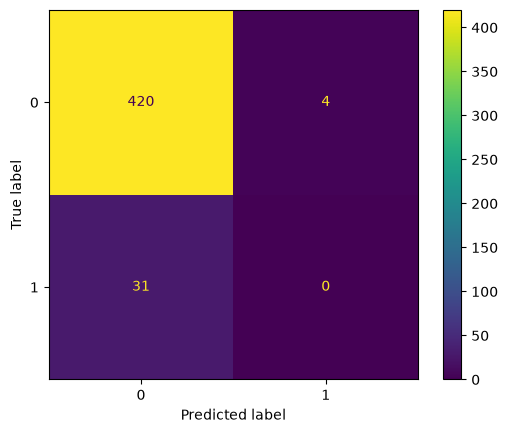

Accuracy: 0.9230769230769231
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [39]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score

logreg = LogisticRegression() #Define the logistic regression function
y_pred = cross_val_predict(logreg, X, y, cv=5) #make the prediction with 5 folds

cm = confusion_matrix(y, y_pred) #Create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm) #create the graph
disp.plot() #plot the graph
plt.show() #show the graph

#calculate metrics
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred)
recall = recall_score(y, y_pred)
f1 = f1_score(y, y_pred)

#print the metrics
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

In [40]:
print(y.value_counts())

HIDEM
0    424
1     31
Name: count, dtype: int64


The dataset is imbalanced because there are more 0s than 1s. This explains the high accuracy (92.31%) and the precision, recall, and F1-score of 0, as the model fails to identify high-demand areas.

In [43]:
#pre-process the data
df = pd.read_csv("2154346boston.csv")

#select features
y= df['HIDEM']
X = df.drop('HIDEM',axis=1) #Select features
X = pd.get_dummies(X, drop_first=True) 

#Normalize the data
columns = X.columns #create index with column names (needed for last step)
scaler = MinMaxScaler() #initiate the scaler
X = scaler.fit_transform(X) #scale the data
X = pd.DataFrame(X,columns=columns) #turn back into a dataframe

In [55]:
#Hyperparameter Tuning
import optuna
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

# Hyperparameter tuning
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 250, step=10),
        'max_depth': trial.suggest_int('max_depth', 10, 250, step=10),
        'min_samples_split': trial.suggest_int('min_samples_split', 10, 30, step=1),
        'max_features': trial.suggest_categorical('max_features', [None, 'sqrt', 'log2']),
        'random_state': 69
    }
    Classifier = RandomForestClassifier(**params)
    score = cross_val_score(Classifier, X, y, cv=5, scoring='accuracy', n_jobs=-1).mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)  # search across 100 different combinations

print("Best params:", study.best_params)

[I 2026-10-30 14:47:42,142] A new study created in memory with name: no-name-80e33b1f-1f05-4b6a-a7cd-75a30e9e5b32
[I 2026-10-30 14:47:49,586] Trial 0 finished with value: 0.9318681318681319 and parameters: {'n_estimators': 10, 'max_depth': 60, 'min_samples_split': 29, 'max_features': 'log2'}. Best is trial 0 with value: 0.9318681318681319.
[I 2026-10-30 14:47:51,069] Trial 1 finished with value: 0.9318681318681319 and parameters: {'n_estimators': 160, 'max_depth': 20, 'min_samples_split': 24, 'max_features': 'log2'}. Best is trial 0 with value: 0.9318681318681319.
[I 2026-10-30 14:47:52,443] Trial 2 finished with value: 0.9318681318681319 and parameters: {'n_estimators': 140, 'max_depth': 20, 'min_samples_split': 18, 'max_features': None}. Best is trial 0 with value: 0.9318681318681319.
[I 2026-10-30 14:47:53,413] Trial 3 finished with value: 0.9318681318681319 and parameters: {'n_estimators': 140, 'max_depth': 130, 'min_samples_split': 28, 'max_features': 'sqrt'}. Best is trial 0 with

Best params: {'n_estimators': 10, 'max_depth': 60, 'min_samples_split': 29, 'max_features': 'log2'}


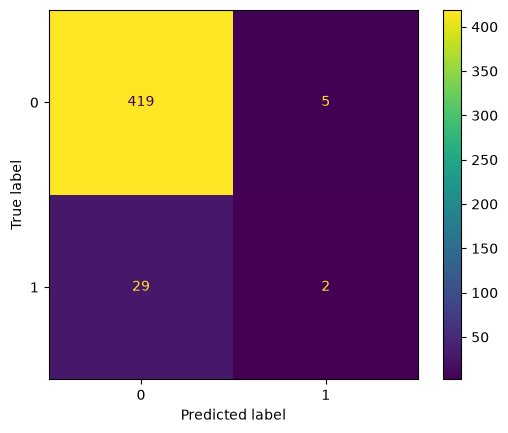

Accuracy: 0.9252747252747253
precision 0.0
recall 0.0
F1 Score 0.0


In [48]:
#Make the prediction
rf = RandomForestClassifier(n_estimators=100, random_state=69)

y_pred = cross_val_predict(rf, X, y, cv=5) #make the predictions

cm = confusion_matrix(y, y_pred) #create the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm) #create the graph
disp.plot() #plot the graph
plt.show() #show the graph

accuracy = (cm.diagonal().sum()) / cm.sum() #calculate accuracy
print("Accuracy:",accuracy) #print accuracy
print("precision", precision)
print("recall", recall)
print("F1 Score", f1)